# 05 Learning

978 areas have a rule type but no published hours. Predict them from nearby areas of the same
class, and decide where not to: a wrong "free" costs a driver a fine. Every quoted number comes
from [`analysis/learning.py`](../../analysis/learning.py) through the report's generator.

*Runs offline in about ten seconds.*

In [1]:
import os
import sys
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pipeline").is_dir()))
sys.path.insert(0, "analysis")

import geopandas as gpd
import pandas as pd
from IPython.display import Markdown

import learning
import report_stats as rs

pd.set_option("display.max_colwidth", None)
areas = gpd.read_parquet(rs.SOURCE)
results = rs.learning_results(areas)   # the simulation, the cut-off, the predictions: run once
labelled, targets = results["labelled"], results["targets"]

## 1. The task

Supervised classification: the label is an area's hours pattern, such as
`{"mon_fri": [9, 21], "sat": [9, 18]}`. We learn from official areas whose rule type needs hours,
and predict the `missing_hours` ones.

In [2]:
pd.DataFrame({
    "labelled": labelled["luokka"].value_counts(),
    "to predict": targets["luokka"].value_counts(),
    "patterns": labelled.groupby("luokka")["hours"].nunique(),
    "most common %": labelled.groupby("luokka")["hours"].agg(lambda s: round(100 * s.value_counts().iloc[0] / len(s), 1)),
}).fillna(0).astype({"to predict": int}).rename(index=int).rename_axis("class")

,labelled,to predict,patterns,most common %
class,,,,
1,52,353,9,36.5
2,12,18,1,100.0
3,25,0,4,64.0
4,78,3,2,98.7
5,458,56,6,51.1
6,2585,437,5,50.3
7,400,29,5,70.5
8,1587,10,7,92.9
9,234,36,21,53.8


Class 1, free short-term parking, is the hard part: over a third of the areas to predict, but
only 52 labelled examples spread over 9 patterns.

## 2. Model

A distance-weighted vote of the *k* nearest labelled areas of the same class. Exploration showed
that location within a class carries the signal ([04](04_exploration.ipynb), §8). The canvas also
planned a same-street feature; the register has no street names, so there is none. For a few areas
we must predict:

In [3]:
results["predicted"].join(targets[["luokka", "district"]]).head().assign(predicted=lambda d: d["predicted"].map(rs.readable))

,predicted,nearest,share,answer,luokka,district
137,"mon_fri 9-21, sat 9-18",75.537552,1.000000,True,7.0,ULLANLINNA
189,"mon_fri 9-21, sat 9-18",25.142237,1.000000,True,6.0,ULLANLINNA
307,mon_fri 8-20,68.433944,1.000000,True,8.0,LAUTTASAARI
316,mon_fri 8-20,115.181693,1.000000,True,8.0,LAUTTASAARI
349,mon_fri 8-17,90.278572,0.719851,False,1.0,LAUTTASAARI


## 3. Tested where it will be used

The 97.5% from exploration was measured with a neighbour 0-10 m away. The areas we must predict
sit a median of about 150 m from one. So for each of them, a random labelled area **of the same
class** stands in, with its neighbours hidden out to that area's real distance, and we predict it:
the targets' class mix and distances, with known answers. Twenty rounds. A second test holds out
whole districts.

An answer is **unsafe** when the true rule applies at an hour of the week where the prediction
says it does not: the app would say free or allowed where the driver must pay or move.

In [4]:
Markdown(rs.learning_scores(results))

### Predicting the missing hours, at the distances they really face

| Method                                            |   Accuracy % |   Macro F1 |   Unsafe % |
|:--------------------------------------------------|-------------:|-----------:|-----------:|
| most common pattern                               |         28.3 |      0.012 |       43   |
| most common pattern of the class                  |         48.1 |      0.047 |       26.6 |
| Nearest neighbours, k=1                           |         60.7 |      0.206 |       22.7 |
| Nearest neighbours, k=3                           |         61.7 |      0.204 |       23.3 |
| Nearest neighbours, k=5                           |         61.8 |      0.186 |       24.2 |
| Nearest neighbours, k=5, whole districts held out |         63.8 |      0.105 |       13.6 |


At the real distances the model beats the class baseline, 62% against 48%, and nearly a quarter
of its answers are unsafe. Used everywhere, it would cause fines.

## 4. The cut-off

Set on 24 October, before any result: answer only where the test reaches **95% accuracy and under
1% unsafe**. The cut-off is chosen on half the rounds and measured on the other half, and on whole
districts held out:

In [5]:
Markdown(rs.learning_cutoff(results))

Cut-off: the 5 nearest same-class areas, the nearest within 150 m, all agreeing. Target, fixed before any result: at least 95% accurate and under 1% unsafe. Of the 978 areas without hours, **373** get an answer.

### The cut-off, on tests it was not chosen on

| Test                                     |   Answered % |   Accuracy % |   Unsafe % |
|:-----------------------------------------|-------------:|-------------:|-----------:|
| Simulation, rounds not used to choose it |         35.5 |         99.4 |        0.3 |
| Whole districts held out                 |          6.9 |         98.5 |        0   |


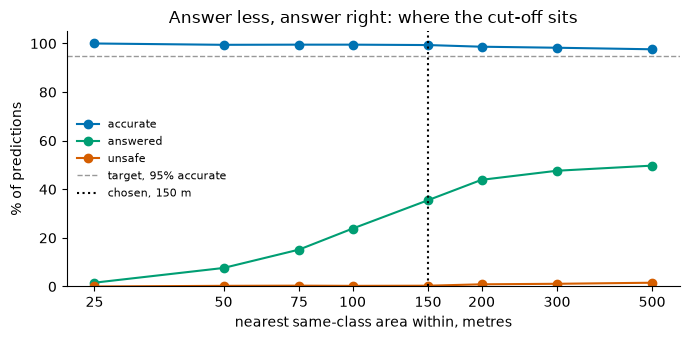

In [6]:
rs.plot_cutoff(results);

Unsafe answers, not accuracy, set the limit: with five neighbours agreeing, accuracy stays high
even at 500 m, while unsafe answers pass 1% beyond about 200 m.

## 5. Who it answers

In [7]:
Markdown(rs.learning_by_class(results))

### The cut-off by parking class

|   Class |   To predict |   Answered |   Simulated accuracy % |   Simulated unsafe % |   Simulated answers |
|--------:|-------------:|-----------:|-----------------------:|---------------------:|--------------------:|
|       1 |          353 |          1 |                   81.8 |                 18.2 |                  11 |
|       2 |           18 |          0 |                        |                      |                   0 |
|       4 |            3 |          3 |                  100   |                  0   |                  29 |
|       5 |           56 |         29 |                   98.5 |                  1   |                 201 |
|       6 |          437 |        314 |                   99.5 |                  0.2 |                2970 |
|       7 |           29 |         10 |                   98.5 |                  1.5 |                  68 |
|       8 |           10 |         10 |                  100   |                  0   |                  96 |
|       9 |           36 |          4 |                  100   |                  0   |                  18 |
|      10 |           36 |          2 |                  100   |                  0   |                  16 |


Class 6 is answered mostly; class 1 almost never, since its few neighbours rarely agree. Classes 5
and 7 sit at 1.0-1.5% unsafe in the simulation, on small numbers: at the edge of a bar set for all
classes together.

In [8]:
Markdown(rs.coverage_by_district(areas, results))

### Coverage per district, before and after prediction

| District      |   Areas |   Without hours |   Answered before |   Gained |   Before % |   After % |
|:--------------|--------:|----------------:|------------------:|---------:|-----------:|----------:|
| REIJOLA       |     597 |             330 |               258 |       53 |       43.2 |      52.1 |
| VALLILA       |     569 |             294 |               262 |      230 |       46   |      86.5 |
| ALPPIHARJU    |     305 |             117 |               180 |       46 |       59   |      74.1 |
| MUNKKINIEMI   |     592 |              75 |               508 |        6 |       85.8 |      86.8 |
| PASILA        |     146 |              61 |                74 |        5 |       50.7 |      54.1 |
| HAAGA         |     504 |              30 |               468 |        0 |       92.9 |      92.9 |
| TAKA-TÖÖLÖ    |     554 |              25 |               515 |        1 |       93   |      93.1 |
| ULLANLINNA    |    1330 |              19 |              1281 |       12 |       96.3 |      97.2 |
| LAUTTASAARI   |     790 |               8 |               778 |        5 |       98.5 |      99.1 |
| VIRONNIEMI    |     795 |               7 |               752 |        6 |       94.6 |      95.3 |
| KALLIO        |    1009 |               6 |               941 |        6 |       93.3 |      93.9 |
| KAMPINMALMI   |    1471 |               5 |              1330 |        3 |       90.4 |      90.6 |
| VANHAKAUPUNKI |      48 |               1 |                27 |        0 |       56.2 |      56.2 |


Vallila gains most. Reijola, with the largest gap, gains little: its gap is class 1. Prediction
helps where the register is already dense, and the disc-parking districts stay at *check the sign*.

## 6. Errors

In [9]:
rows = learning.held_out(results["sim"], results["cut"])
def confusions(errors):
    return pd.DataFrame({"truth": errors["truth"].map(rs.readable), "predicted": errors["predicted"].map(rs.readable),
                         "unsafe": errors["unsafe"]}).value_counts().head(5)

print(f"accuracy by class, no cut-off: {rows.groupby('luokka')['correct'].mean().round(2).to_dict()}")
confusions(rows[~rows["correct"]])

accuracy by class, no cut-off: {1.0: 0.11, 4.0: 0.97, 5.0: 0.86, 6.0: 0.96, 7.0: 0.83, 8.0: 1.0, 9.0: 0.46, 10.0: 0.84}


truth                   predicted               unsafe
mon_fri 8-20            mon_fri 8-17            True      418
mon_fri 8-17            mon_fri 8-20            False     317
                        mon_fri 8-17, sat 9-15  False     273
mon_fri 8-17, sat 9-15  mon_fri 8-17            True      245
mon_fri 6-24            mon_fri 8-17            True      196
Name: count, dtype: int64

Without the cut-off, most errors are between near-identical disc patterns, `8-20` against `8-17`,
mostly in class 1, and most errors are unsafe. Among the answers the cut-off lets through:

In [10]:
answered = learning.kept(rows, results["cut"])
print(f"{(~answered['correct']).sum()} wrong of {len(answered)}")
confusions(answered[~answered["correct"]])

22 wrong of 3409


truth                             predicted               unsafe
mon_fri 9-21, sat 9-18            mon_fri 9-21            True      8
mon_fri 9-21                      mon_fri 9-21, sat 9-18  False     7
mon_fri 9-17                      mon_fri 9-21            False     3
mon_fri 7-18                      mon_fri 8-17            True      2
mon_fri 9-21, sat 9-21, sun 9-21  mon_fri 9-21, sat 9-18  True      1
Name: count, dtype: int64

The few that remain are mostly the Saturday question: `9-21` against `9-21, (9-18)`. Predicting no
Saturday hours where Saturday is paid is exactly the unsafe kind.

## 7. Reflection

**Hands on:** hours for 373 of the 978 areas, at 99% in the test, ready to show as labelled
estimates in the app.

**The canvas planned** same-class nearest neighbours on neighbour hours, distance, same street,
class and district; accuracy and macro F1 against a dummy baseline; district-blocked validation; a
test at the real distances; a cut-off favouring accuracy.

**What worked:** testing at the real distances set an honest expectation, 62% rather than 97.5%,
and the cut-off turned a weak model into a strict one.

**What did not, and why:** class 1, the largest group, gets almost nothing; rare patterns are
rarely predicted (macro F1 about 0.2); holding out whole districts leaves too few close neighbours
to answer more than 7%.

**What changed:** no same-street feature, for lack of street names; the test matched class as well
as distance; a second, class-level baseline; the unsafe rate, which became the binding limit.

**Imputation, for a driver:** 373 more answers, labelled as estimates, about 3 in 1,000 of them
unsafe in the test. The gains go to the centre-adjacent paid districts; the suburbs and the disc
districts keep *check the sign*.

**What we would do differently:** define the unsafe measure first. It decided more than accuracy did.

**Future steps:** more labelled data for class 1, from traffic signs or drivers; a cut-off per
class; predicting whole streets rather than single areas.

**Experience and learning:** the validation design mattered more than the model. A simple model
with an honest test and the right to abstain beats a better one tested on easy cases.

> *Each of us: one line on what you took from this stage.*